# Association Rules — Product Recommendation System
**Owners:** Team B: Marwan, Moaaz

In [1]:
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from mlxtend.frequent_patterns import apriori, association_rules

RANDOM_STATE = 42

## A. Dataset
**Owner:** Marwan

**Online Retail** (UCI Machine Learning Repository, id 352): https://archive.ics.uci.edu/dataset/352/online+retail

All transactions of a UK-based online gift shop between 01/12/2010 and 09/12/2011. Each row is one product line of one invoice.
The dataset has no target column: association rule mining is unsupervised.

In [2]:
online_retail = fetch_ucirepo(id=352)

# InvoiceNo is stored in .ids, the remaining columns in .features
df_raw = pd.concat([online_retail.data.ids, online_retail.data.features], axis=1)

print("Shape (rows, columns):", df_raw.shape)
print("Invoices:", df_raw["InvoiceNo"].nunique(), "| Products:", df_raw["Description"].nunique())
df_raw.head()

Shape (rows, columns): (541909, 8)
Invoices: 25900 | Products: 4223


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## B. Preprocessing
**Owner:** Marwan

Data quality before cleaning:

In [3]:
print("Missing values per column:")
print(df_raw.isnull().sum())
print()
print("Exact duplicate rows:   ", df_raw.duplicated().sum())
print("Non-positive quantities:", (df_raw["Quantity"] <= 0).sum())
print("Cancelled invoices:     ", df_raw["InvoiceNo"].astype(str).str.startswith("C").sum())

Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Exact duplicate rows:    5268
Non-positive quantities: 10624
Cancelled invoices:      9288


In [4]:
df = df_raw.copy()

df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
df = df[~df["InvoiceNo"].str.startswith("C")]      # cancelled invoices
df = df[df["Quantity"] > 0]                         # returns and corrections

df = df.dropna(subset=["Description"])
df["Description"] = df["Description"].astype(str).str.strip()

df = df.drop_duplicates()
df = df[df["Description"] != "POSTAGE"]             # shipping charge, not a product

print(f"Rows before cleaning: {len(df_raw)}")
print(f"Rows after cleaning:  {len(df)}")
print(f"Rows removed:         {len(df_raw) - len(df)}")

df["Country"].value_counts().head(10)

Rows before cleaning: 541909
Rows after cleaning:  524336
Rows removed:         17573


Country
United Kingdom    480499
Germany             8653
France              8093
EIRE                7883
Spain               2418
Netherlands         2326
Belgium             1935
Switzerland         1928
Portugal            1462
Australia           1183
Name: count, dtype: int64

In [5]:
df_germany = df[df["Country"] == "Germany"]

# one row per invoice, one column per product; a product bought twice in one invoice is summed
basket = df_germany.groupby(["InvoiceNo", "Description"])["Quantity"].sum().unstack().fillna(0)
basket_bool = basket > 0

top_10_items = basket_bool.sum().sort_values(ascending=False).head(10)
basket_sizes = basket_bool.sum(axis=1)

print("Basket matrix (invoices, products):", basket_bool.shape)
basket_bool.iloc[:5, :5]

Basket matrix (invoices, products): (449, 1694)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND
InvoiceNo,,,,,
536527,False,False,False,False,False
536840,False,False,False,False,False
536861,False,False,False,False,False
536967,False,False,False,False,False
536983,False,False,False,False,False


**Notes on preprocessing choices:**
- **Germany only:** keeps the basket matrix small enough for Apriori (449 invoices × 1,694 products); Apriori's cost grows with the number of items and transactions.
- **POSTAGE removed:** it is a shipping charge, not a product, and would appear in almost every rule.
- **Feature scaling and imbalance handling are not applicable:** the basket is binary (bought / not bought) and there is no target class.

## C. Train/Test Split
**Owner:** Moaaz

Rules are mined on 80% of the invoices; the remaining 20% are held out for evaluation in section E.

In [6]:
basket_train, basket_test = train_test_split(basket_bool, test_size=0.2, random_state=RANDOM_STATE)

print("Train invoices:", len(basket_train), "| Test invoices:", len(basket_test))

Train invoices: 359 | Test invoices: 90


## Frequent Itemsets and Rules
**Owner:** Moaaz

`apriori` with `min_support = 0.03`, then `association_rules` filtered to lift > 1.

In [7]:
freq = apriori(basket_train, min_support=0.03, use_colnames=True)
rules = association_rules(freq, metric="lift", min_threshold=1)

print("Frequent itemsets:", len(freq))
print("Rules:", len(rules))

Frequent itemsets: 253
Rules: 246


## D. Predict New Values
**Owner:** Moaaz

`recommend()` keeps the rules whose antecedent is fully contained in the basket, ranks them by confidence (lift breaks ties), and returns the consequents the customer does not already have.

In [8]:
def recommend(items, rules, top_n=5):
    basket = set(items)

    matching = rules[rules["antecedents"].apply(lambda lhs: lhs.issubset(basket))]
    matching = matching.sort_values(["confidence", "lift"], ascending=False)

    result = []
    for consequent in matching["consequents"]:
        for product in consequent:
            if product not in basket and product not in result:
                result.append(product)

    return result[:top_n]


print(recommend(["SET OF 12 FAIRY CAKE BAKING CASES"], rules))
print(recommend(["SPACEBOY CHILDRENS CUP"], rules))
print(recommend(["NOT A REAL PRODUCT"], rules))

['SET OF 12 MINI LOAF BAKING CASES']
['SPACEBOY CHILDRENS BOWL']
[]


## E. Predicted vs Actual
**Owner:** Moaaz

For each test invoice with at least two items, one item is hidden at random. `recommend()` receives the rest, and the result counts as a hit if the hidden item is among the suggestions.

In [9]:
rng = random.Random(RANDOM_STATE)
hits, misses, no_rec, skipped = 0, 0, 0, 0

for invoice, row in basket_test.iterrows():
    items = list(row[row].index)
    if len(items) < 2:
        skipped += 1
        continue

    hidden = rng.choice(items)
    visible = [i for i in items if i != hidden]
    suggestions = recommend(visible, rules)

    if not suggestions:
        no_rec += 1
    elif hidden in suggestions:
        hits += 1
    else:
        misses += 1

tested = hits + misses + no_rec
print("Skipped (1 item):", skipped, "| Tested:", tested)
print("Hits:", hits, "| Misses:", misses, "| No recommendation:", no_rec)
print(f"Hit rate: {hits / tested:.1%}")
print(f"Hit rate when a recommendation was made: {hits / (hits + misses):.1%}")

Skipped (1 item): 4 | Tested: 86
Hits: 5 | Misses: 60 | No recommendation: 21
Hit rate: 5.8%
Hit rate when a recommendation was made: 7.7%


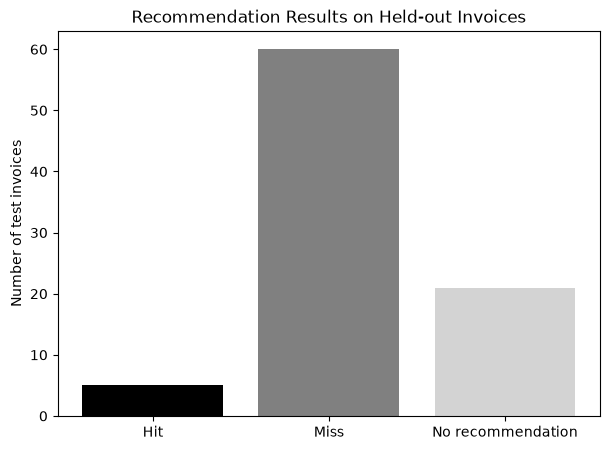

In [10]:
plt.figure(figsize=(7, 5))
plt.bar(["Hit", "Miss", "No recommendation"], [hits, misses, no_rec], color=["black", "grey", "lightgrey"])
plt.title("Recommendation Results on Held-out Invoices")
plt.ylabel("Number of test invoices")
plt.show()

## F. Evaluation Metrics
**Owner:** Moaaz

Top 10 rules by lift, with support, confidence and lift.

In [11]:
rules.sort_values("lift", ascending=False).head(10)[["antecedents", "consequents", "support", "confidence", "lift"]]

,antecedents,consequents,support,confidence,lift
150,frozenset({SET OF 12 FAIRY CAKE BAKING CASES}),frozenset({SET OF 12 MINI LOAF BAKING CASES}),0.033426,0.750000,17.950000
151,frozenset({SET OF 12 MINI LOAF BAKING CASES}),frozenset({SET OF 12 FAIRY CAKE BAKING CASES}),0.033426,0.800000,17.950000
156,frozenset({SPACEBOY CHILDRENS CUP}),frozenset({SPACEBOY CHILDRENS BOWL}),0.041783,0.833333,17.598039
157,frozenset({SPACEBOY CHILDRENS BOWL}),frozenset({SPACEBOY CHILDRENS CUP}),0.041783,0.882353,17.598039
20,frozenset({CHILDRENS CUTLERY SPACEBOY}),frozenset({CHILDRENS CUTLERY DOLLY GIRL}),0.041783,0.833333,14.958333
21,frozenset({CHILDRENS CUTLERY DOLLY GIRL}),frozenset({CHILDRENS CUTLERY SPACEBOY}),0.041783,0.750000,14.958333
160,frozenset({WHITE SPOT BLUE CERAMIC DRAWER KNOB}),frozenset({WHITE SPOT RED CERAMIC DRAWER KNOB}),0.030641,0.785714,14.845865
161,frozenset({WHITE SPOT RED CERAMIC DRAWER KNOB}),frozenset({WHITE SPOT BLUE CERAMIC DRAWER KNOB}),0.030641,0.578947,14.845865
22,frozenset({COFFEE MUG PEARS DESIGN}),frozenset({COFFEE MUG APPLES DESIGN}),0.036212,0.928571,14.493789
23,frozenset({COFFEE MUG APPLES DESIGN}),frozenset({COFFEE MUG PEARS DESIGN}),0.036212,0.565217,14.493789


## G. Supporting Visualizations
**Owner:** Marwan, Moaaz

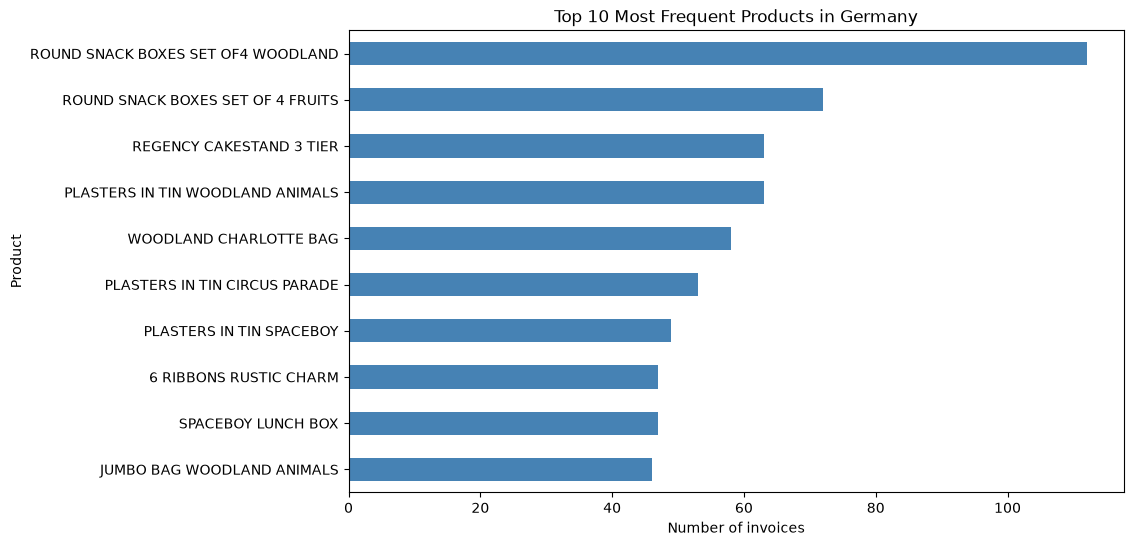

In [12]:
plt.figure(figsize=(10, 6))
top_10_items.plot(kind="barh", color="steelblue")
plt.gca().invert_yaxis()
plt.title("Top 10 Most Frequent Products in Germany")
plt.xlabel("Number of invoices")
plt.ylabel("Product")
plt.show()

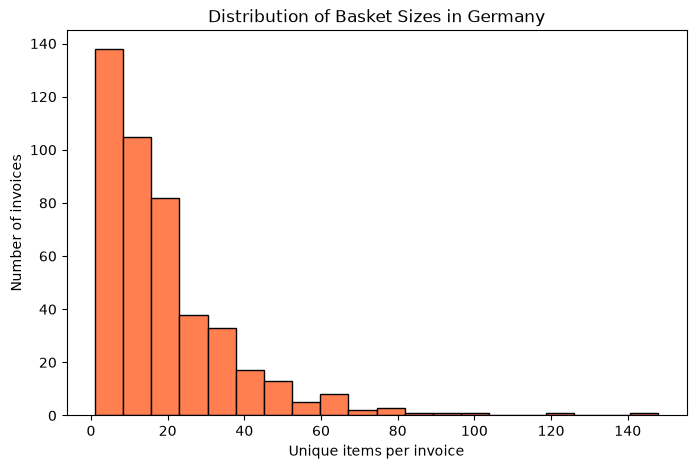

In [13]:
plt.figure(figsize=(8, 5))
basket_sizes.plot(kind="hist", bins=20, color="coral", edgecolor="black")
plt.title("Distribution of Basket Sizes in Germany")
plt.xlabel("Unique items per invoice")
plt.ylabel("Number of invoices")
plt.show()

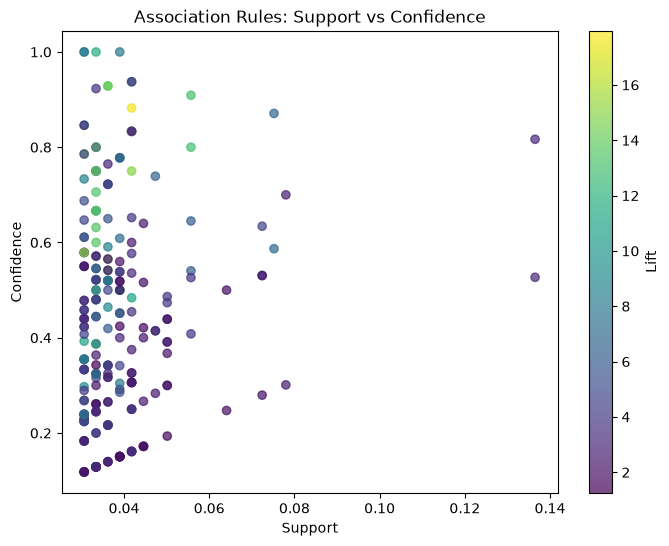

In [14]:
plt.figure(figsize=(8, 6))
points = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", alpha=0.7)
plt.colorbar(points, label="Lift")
plt.title("Association Rules: Support vs Confidence")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.show()

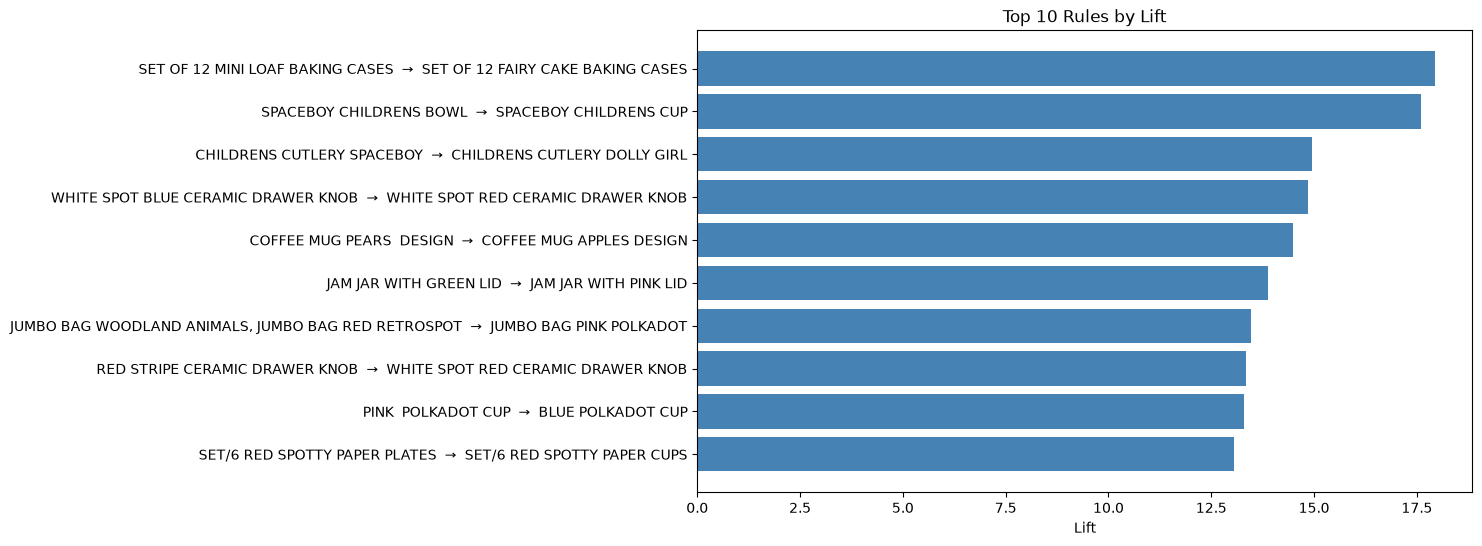

In [15]:
# one direction per product pair (A → B and B → A share the same lift)
ranked = rules.sort_values(["lift", "confidence"], ascending=False)
pair = ranked.apply(lambda r: r["antecedents"] | r["consequents"], axis=1)
top = ranked[~pair.duplicated()].head(10)

labels = top["antecedents"].apply(", ".join) + "  →  " + top["consequents"].apply(", ".join)

plt.figure(figsize=(10, 6))
plt.barh(labels, top["lift"], color="steelblue")
plt.gca().invert_yaxis()
plt.title("Top 10 Rules by Lift")
plt.xlabel("Lift")
plt.show()